# MMS Case 12 - Reproducible Verification Pipeline

This notebook reproduces, end to end, the Method-of-Manufactured-Solutions
(MMS) verification pipeline for **Case 12** of the original Fortran solver
(`src/fortran_original/4Order_LPOG_Euler/case_12.f`), as ported to the
`mms_viscoelastic` Python package.

It covers four steps:

1. **Exact manufactured fields** - evaluate and visualize `u`, `v`, `psi`,
   `wz`, `txx`, `txy`, `tyy` on a structured grid.
2. **Source terms** - evaluate the manufactured forcing terms `tfwz`,
   `tfTxx`, `tfTxy`, `tfTyy`.
3. **Fortran-reference validation** - compare the Python source terms against
   CSV files exported by an independent Fortran program.
4. **Grid-convergence verification** - confirm that the finite-difference
   operators reproduce the exact stream-function identities
   (`u = d(psi)/dy`, `v = -d(psi)/dx`, `wz = d(u)/dy - d(v)/dx`) at second
   order.

Background and full derivations are in
[`docs/case-12-convergence-verification.md`](../../docs/case-12-convergence-verification.md)
and
[`docs/case-12-complete-validation-report.md`](../../docs/case-12-complete-validation-report.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mms_viscoelastic.grids import Grid2D
from mms_viscoelastic.manufactured_solutions import evaluate_case_12_exact
from mms_viscoelastic.source_terms import evaluate_case_12_source_terms
from mms_viscoelastic.validation import (
    compare_case12_tftxx_reference,
    compare_case12_tftxy_reference,
    compare_case12_tftyy_reference,
    compare_case12_tfwz_reference,
)
from mms_viscoelastic.visualization import plot_case12_panel
from mms_viscoelastic.numerics import QUANTITIES, run_convergence_study

%matplotlib inline

## 1. Exact manufactured fields

The exact fields are evaluated on a uniform grid over the unit square
$[0,1]^2$ at $t = 0$, using the default Case 12 parameters
(`beta = 0.5`, `at = 0`, all trigonometric stress coefficients equal to 1).

In [2]:
grid = Grid2D.from_bounds(nx=65, ny=65)
field = evaluate_case_12_exact(grid, t=0.0)

for component in field.available_components():
    values = getattr(field, component)
    print(f"{component:>3s}: min={values.min(): .6e}, max={values.max(): .6e}")

  u: min=-3.477483e-01, max= 7.853982e-01
  v: min=-4.485084e-01, max= 4.485084e-01
psi: min=-1.447795e-01, max= 0.000000e+00
 wz: min=-3.638707e+00, max= 4.852189e+00
txx: min= 7.498799e-33, max= 2.914214e+00
txy: min= 7.498799e-33, max= 2.914214e+00
tyy: min= 7.498799e-33, max= 2.914214e+00


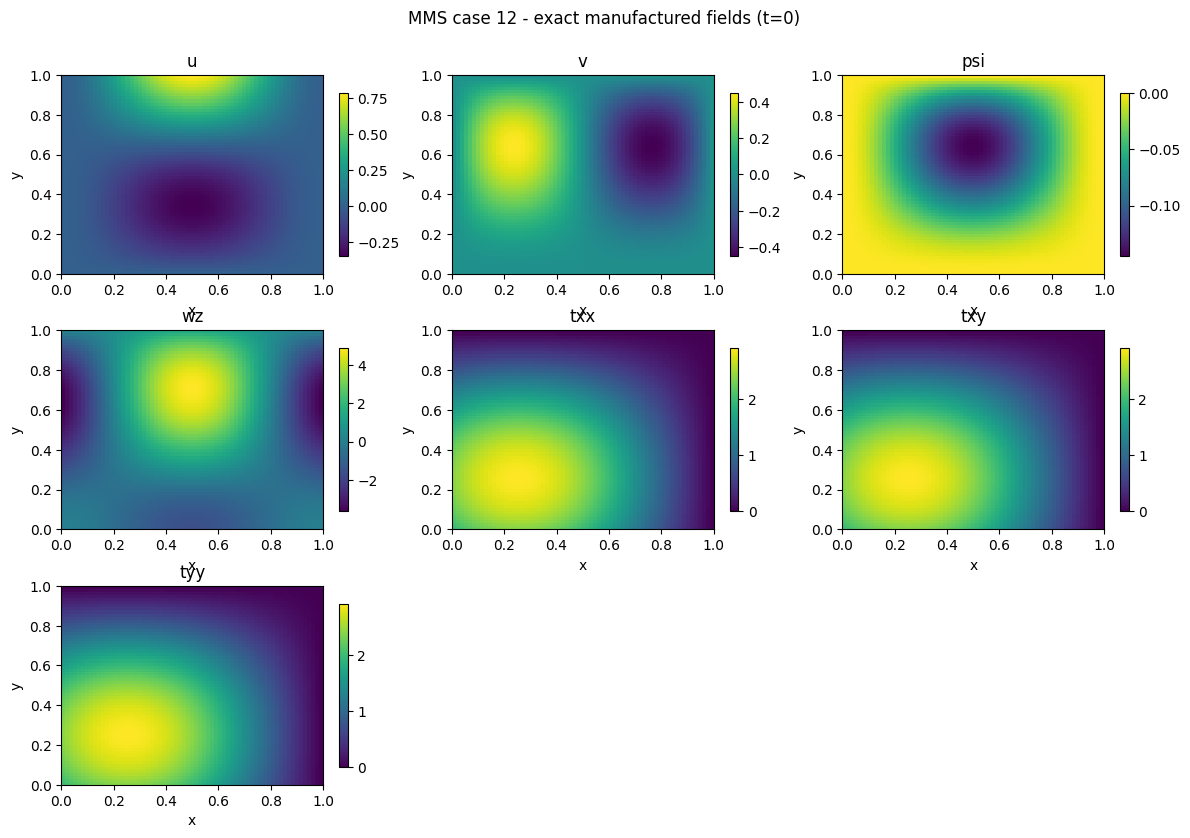

In [3]:
fig = plot_case12_panel(grid, field, title="MMS case 12 - exact manufactured fields (t=0)")
fig.set_size_inches(12, 8)
plt.show()

## 2. Source terms

The manufactured forcing terms `tfwz`, `tfTxx`, `tfTxy`, `tfTyy` are the
right-hand sides that the original Fortran solver must reproduce so that the
exact fields above satisfy the governing equations identically. They are
evaluated with the default `Case12SourceTermParameters`
(`Re = 1`, `Wi = 1`, `beta = 0.5`, `epsilon = xi = alpha_g = at = 0`).

In [4]:
terms = evaluate_case_12_source_terms(grid)

for name in ("tfwz", "tfTxx", "tfTxy", "tfTyy"):
    values = getattr(terms, name)
    print(f"{name:>5s}: min={values.min(): .6e}, max={values.max(): .6e}")

 tfwz: min=-9.432027e+01, max= 9.862450e+01
tfTxx: min=-7.175611e+00, max= 1.219593e+01
tfTxy: min=-6.137395e+00, max= 7.974791e+00
tfTyy: min=-1.103589e+01, max= 1.214111e+01


## 3. Fortran-reference validation

Each source term is compared, point by point, against a CSV file produced by
an independent Fortran program
(`validation/fortran_reference/case12_<term>/case12_<term>_reference.f90`) on
small `3 x 3` grids. The acceptance criterion is
`max_abs_error < 1e-10` (`1e-11` for `tfwz`).

In [5]:
results = {
    "tfwz": compare_case12_tfwz_reference(
        "validation/reference_data/case12_tfwz_3x3_default.csv"
    ),
    "tfTxx": compare_case12_tftxx_reference(
        "validation/reference_data/case12_tfTxx_3x3_default.csv"
    ),
    "tfTxy": compare_case12_tftxy_reference(
        "validation/reference_data/case12_tfTxy_3x3_default.csv"
    ),
    "tfTyy": compare_case12_tftyy_reference(
        "validation/reference_data/case12_tfTyy_3x3_default.csv"
    ),
}

summary = pd.DataFrame(
    {
        "max_abs_error": [r.max_abs_error for r in results.values()],
        "max_rel_error": [r.max_rel_error for r in results.values()],
        "passed": [r.passed for r in results.values()],
    },
    index=list(results.keys()),
)
summary

,max_abs_error,max_rel_error,passed
tfwz,7.105427e-15,1.439861e-16,True
tfTxx,4.440892e-16,2.066104e-16,True
tfTxy,8.881784e-16,1.498532e-16,True
tfTyy,1.732348e-20,1.732348e-20,True


## 4. Grid-convergence verification

`run_convergence_study` evaluates the exact Case 12 fields on grids with
`n = 8, 16, 32, 64` cells per direction and checks the discrete
stream-function identities

```text
u  = d(psi)/dy
v  = -d(psi)/dx
wz = d(u)/dy - d(v)/dx
```

using the second-order operators `derivative_x` / `derivative_y`. These three
identities were verified symbolically (SymPy) to be exact for the Case 12
manufactured solution, so any deviation between the discrete estimate and the
exact field is pure discretization error (see
`docs/case-12-convergence-verification.md`, Section 1).

In [6]:
report = run_convergence_study([8, 16, 32, 64])

rows = report.to_rows()
table = pd.DataFrame(rows)
table

,n,h,l2_u,linf_u,l2_v,linf_v,l2_wz,linf_wz
0,8,0.125000,0.009172,0.023664,0.029823,0.080473,0.118749,0.283622
1,16,0.062500,0.002360,0.008083,0.006457,0.017869,0.031906,0.073138
2,32,0.031250,0.000583,0.002279,0.001497,0.004058,0.007891,0.020519
3,64,0.015625,0.000143,0.000601,0.000362,0.000954,0.001926,0.005496


In [7]:
print("Estimated order of accuracy (log-log fit across all grids):")
for quantity in QUANTITIES:
    print(
        f"  {quantity:>3s}: L2 order = {report.l2_orders[quantity]:.4f}, "
        f"Linf order = {report.linf_orders[quantity]:.4f}"
    )

Estimated order of accuracy (log-log fit across all grids):
    u: L2 order = 2.0021, Linf order = 1.7726
    v: L2 order = 2.1198, Linf order = 2.1332
   wz: L2 order = 1.9854, Linf order = 1.8902


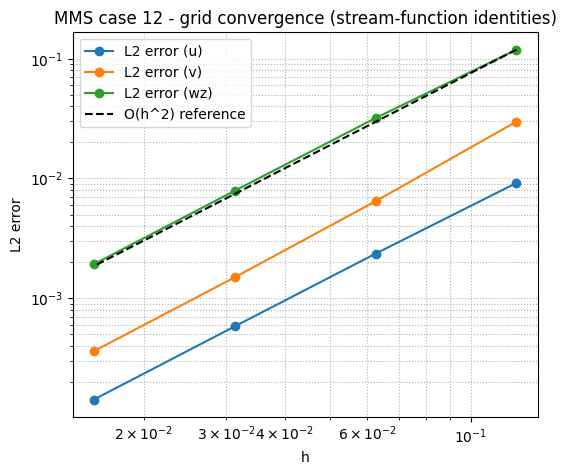

In [8]:
h_values = np.array([level.h for level in report.levels])

fig, ax = plt.subplots(figsize=(6, 5))
for quantity in QUANTITIES:
    l2_values = np.array([level.l2_errors[quantity] for level in report.levels])
    ax.loglog(h_values, l2_values, marker="o", label=f"L2 error ({quantity})")

reference = h_values**2 * report.levels[0].l2_errors["wz"] / h_values[0] ** 2
ax.loglog(h_values, reference, "k--", label="O(h^2) reference")

ax.set_xlabel("h")
ax.set_ylabel("L2 error")
ax.set_title("MMS case 12 - grid convergence (stream-function identities)")
ax.legend()
ax.grid(True, which="both", ls=":")
plt.show()

## 5. Summary

- The exact Case 12 fields (`u`, `v`, `psi`, `wz`, `txx`, `txy`, `tyy`) are
  reproduced by `evaluate_case_12_exact` and visualized above.
- All four manufactured source terms (`tfwz`, `tfTxx`, `tfTxy`, `tfTyy`) match
  the independent Fortran reference to within `1e-10` (`1e-11` for `tfwz`).
- The second-order finite-difference operators reproduce the exact
  stream-function identities with observed L2 order `~2.0` for `u`, `v` and
  `wz` across grids `8 -> 16 -> 32 -> 64`, confirming the expected
  discretization accuracy.

These three results together constitute the current MMS verification evidence
for Case 12 in the Python port.